# SurgiVision: validated training and evaluation
Run from this project directory. Install requirements in the selected kernel first.
Original notebook outputs were removed because they include a checkpoint/run mismatch.
The original train/test lists are retained as train/validation for compatibility; **this is not an independent test benchmark**.
For final testing, supply three disjoint, preferably session-grouped lists before training.


In [33]:
from pathlib import Path
import json, shutil, platform
from datetime import datetime, timezone
import torch, ultralytics, yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from dataset_utils import prepare_dataset, NAMES

ROOT = Path.cwd().resolve()
assert (ROOT / 'dataset_utils.py').exists(), 'Open notebook from the project directory'
BASE = ROOT / 'Surgical-Dataset'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
DATASET = ROOT / 'prepared_datasets' / RUN_ID
SPLITS = {
    'train': BASE /'Test-Train_Groups/train-obj_detector.txt',
    'val': BASE / 'Test-Train_Groups/test-obj_detector.txt',
}
# To use a genuine held-out test set, replace SPLITS with disjoint train/val/test lists.
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)


Device: cpu


In [35]:
counts = prepare_dataset(BASE, DATASET, SPLITS)
print('Validated image counts:', counts)
config = {'path': str(DATASET), 'names': NAMES,
          **{split: f'images/{split}' for split in SPLITS}}
CONFIG = DATASET / 'data.yaml'
CONFIG.write_text(yaml.safe_dump(config, sort_keys=False))
print(CONFIG.read_text())


Validated image counts: {'train': 1834, 'val': 784}
path: /Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/20261103T011448501787Z
names:
- Scalpel
- Straight Dissection Clamp
- Straight Mayo Scissor
- Curved Mayo Scissor
train: images/train
val: images/val



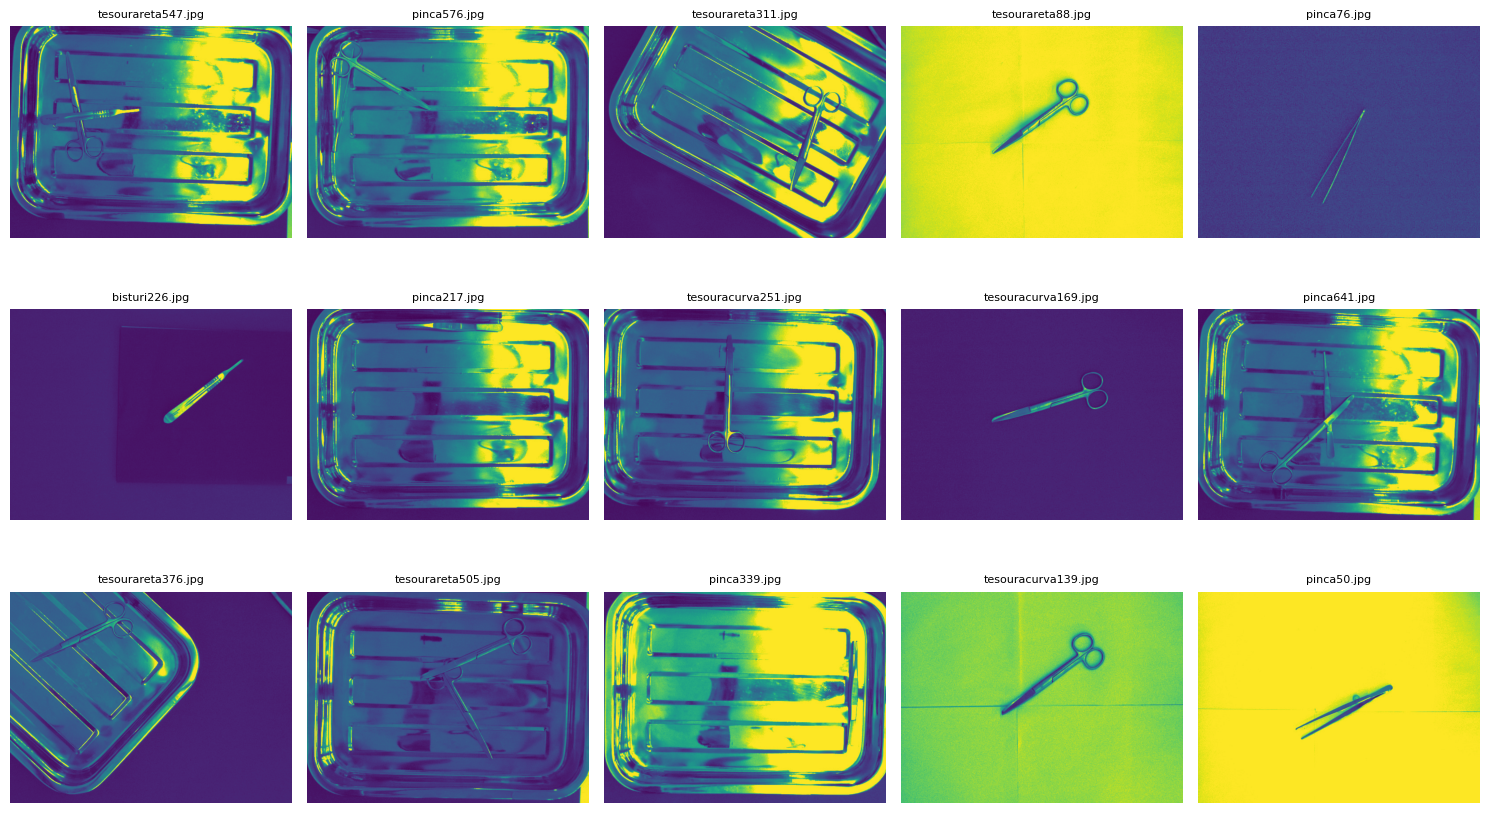

In [37]:
import random
files = sorted((DATASET / 'images/train').iterdir())
samples = random.Random(0).sample(files, min(15, len(files)))
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, path in zip(axes.flat, samples):
    with Image.open(path) as image:
        ax.imshow(image)
    ax.set_title(path.name, fontsize=8)
plt.tight_layout()


In [ ]:
from ultralytics import YOLO
VARIANTS = {'YOLOv8n': 'yolov8n.pt', 'YOLOv8m': 'yolov8m.pt', 'YOLOv9c': 'yolov9c.pt'}
EXPORT_NAMES = {'YOLOv8n': 'v8nbest.pt', 'YOLOv8m': 'v8best.pt', 'YOLOv9c': '9cbest.pt'}
RUN_ROOT = ROOT / 'runs' / RUN_ID
RUN_ROOT.mkdir(parents=True, exist_ok=False)
manifest = {'run_id': RUN_ID, 'dataset_config': str(CONFIG), 'counts': counts,
            'python': platform.python_version(), 'ultralytics': ultralytics.__version__,
            'torch': str(torch.__version__), 'device': str(DEVICE), 'models': {}}
for name, weights in VARIANTS.items():
    model = YOLO(weights)
    model.train(data=str(CONFIG), epochs=100, imgsz=640, batch=16,
                device=DEVICE, project=str(RUN_ROOT), name=name,
                seed=0, deterministic=True, patience=20)
    # Actual trainer output, never a guessed folder name.
    checkpoint = Path(model.trainer.best).resolve()
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    shutil.copy2(checkpoint, ROOT / EXPORT_NAMES[name])
    manifest['models'][name] = {'checkpoint': str(checkpoint), 'export': EXPORT_NAMES[name]}
    (RUN_ROOT / 'manifest.json').write_text(json.dumps(manifest, indent=2))


100%|██████████████████████████████████████| 6.25M/6.25M [00:00<00:00, 7.88MB/s]


New https://pypi.org/project/ultralytics/8.4.199 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.167 🚀 Python-3.12.7 torch-2.6.0 CPU (Apple M2 Pro)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/20261103T011448501787Z/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=Y

train: Scanning /Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/20

train: New cache created: /Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/20261103T011448501787Z/labels/train.cache


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 331.3±129.9 MB/s, size: 56.9 KB)


val: Scanning /Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/2026

val: New cache created: /Users/aathiabhishek/Desktop/SurgiVision-AI/prepared_datasets/20261103T011448501787Z/labels/val.cache


Plotting labels to /Users/aathiabhishek/Desktop/SurgiVision-AI/runs/20261103T011448501787Z/YOLOv8n/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.00125, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to /Users/aathiabhishek/Desktop/SurgiVision-AI/runs/20261103T011448501787Z/YOLOv8n
Starting training for 100 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/100         0G       1.11      2.725      1.249         34        640: 1
                 Class     Images  Instances      Box(P          R      mAP50  m

                   all        784       1087      0.424      0.654       0.47      0.358

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size



      2/100         0G       1.11       2.23      1.232         54        640:  

## Evaluation
Validation scores are for development. Test scores are produced only when you explicitly provide a separate test split. Do not tune thresholds or choose models using the test results.


In [ ]:
metrics_rows = []
for name, item in manifest['models'].items():
    model = YOLO(item['checkpoint'])
    for split in (['val', 'test'] if 'test' in SPLITS else ['val']):
        metrics = model.val(data=str(CONFIG), split=split, imgsz=640, batch=16,
                            device=DEVICE, project=str(RUN_ROOT), name=f'{name}_{split}')
        metrics_rows.append({'Model': name, 'Split': split,
            'mAP50': float(metrics.box.map50), 'mAP50-95': float(metrics.box.map),
            'Precision': float(metrics.box.mp), 'Recall': float(metrics.box.mr)})
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(RUN_ROOT / 'model_comparison.csv', index=False)
print(metrics_df.to_string(index=False))
metrics_df.set_index(['Model', 'Split']).plot.bar(ylim=(0, 1), figsize=(12, 5))
plt.title('YOLOv8n / YOLOv8m / YOLOv9c evaluation')
plt.tight_layout()
